# 02 - Baseline: TF-IDF + One-vs-Rest Logistic Regression
Quy trình: chuẩn hoá (`src/preprocess.py`) -> TF-IDF -> OvR LogisticRegression (28 bộ phân loại độc lập).
Siêu tham số chọn **chỉ trên val** (Macro-F1 tại ngưỡng 0.5). Test chỉ đánh giá một lần với cấu hình đã chốt.
Xác suất val/test được lưu ra `results/preds/` trước khi áp ngưỡng.

> **Cách đọc/chạy.** Đầu vào: dữ liệu như notebook 01 và `src/` (data, preprocess, metrics). Đầu ra: xác suất val/test ở `results/preds/tfidf_lr_*.npz`, bảng ở `results/tables/`, hình ngưỡng ở `results/figures/`. Chạy mất vài phút trên CPU.
>
> **Các chỉ số dùng trong báo cáo (tính ở ngưỡng 0.5 trừ khi nói khác):**
> - **Macro-F1**: trung bình F1 của từng nhãn, mỗi nhãn nặng như nhau (nhạy với nhãn hiếm). **Micro-F1**: gộp mọi cặp (mẫu, nhãn) rồi tính F1 một lần (nhạy với nhãn phổ biến).
> - **Hamming Loss**: tỉ lệ ô (mẫu, nhãn) bị đoán sai; thấp là tốt, nhưng vì đa số ô là âm nên chỉ số này dễ "đẹp" khi mô hình dự đoán ít nhãn dương.
> - **LRAP** và **mAP**: đo chất lượng *xếp hạng* nhãn theo xác suất, không phụ thuộc ngưỡng.
> - **Ngưỡng tau**: nhãn được dự đoán là có nếu xác suất >= tau. **tau\*** là ngưỡng chọn theo val.
> - **Subset accuracy** (đúng cả 28 nhãn) chỉ để tham khảo vì quá khắt khe cho multi-label.

In [1]:
# Khởi tạo: nạp thư viện, dữ liệu và chuẩn hoá văn bản.
# - normalize() (src/preprocess.py): unescape HTML, đổi thẻ <br> thành khoảng trắng, chuẩn hoá Unicode NFC. Giữ nguyên emoji và dấu câu.
# - Y[s]: ma trận nhãn 0/1 (số mẫu x 28); tiers: nhóm head/mid/tail dùng khi báo cáo theo nhóm tần suất.
import sys, time, json, itertools, os, platform
sys.path.insert(0, '..')
import numpy as np, pandas as pd, sklearn, scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from src.data import *
from src.preprocess import normalize
from src.metrics import *

np.random.seed(SEED)
os.makedirs('../results/preds', exist_ok=True)
data = load_all()
for s in data: data[s]['clean'] = data[s].text.map(normalize)
Y = {s: label_matrix(data[s]) for s in data}
tiers = label_tiers(Y['train'].sum(0))
print('sklearn', sklearn.__version__, '| python', platform.python_version())

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sklearn 1.9.0 | python 3.12.4


## 1. Vector hoá
Token = từ (`\w+`) hoặc ký tự đơn không phải chữ/khoảng trắng, nên **emoji và dấu câu được giữ làm token**.
Hai cấu hình đặc trưng: `word` (1-2 gram) và `word+char` (thêm char_wb 2-4 gram, để bắt teencode/kéo dài ký tự). TF-IDF chỉ fit trên train.

In [2]:
# Vector hoá TF-IDF, fit CHỈ trên train (val/test chỉ transform để không rò rỉ thông tin).
# - TOKEN: lấy từ (\w+) hoặc 1 ký tự không phải chữ/khoảng trắng, nên emoji và dấu câu trở thành token riêng.
# - Hai cấu hình đặc trưng: 'word' (unigram + bigram) và 'word+char' (thêm n-gram ký tự 2-4 trong từ, để bắt teencode/kéo dài ký tự).
# - sublinear_tf: dùng 1+log(tf) để giảm ảnh hưởng của từ lặp nhiều; min_df: bỏ n-gram quá hiếm.
TOKEN = r"(?u)\b\w+\b|[^\w\s]"
def build_vec(kind):
    w = TfidfVectorizer(lowercase=True, token_pattern=TOKEN, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    if kind == 'word': return [w]
    c = TfidfVectorizer(lowercase=True, analyzer='char_wb', ngram_range=(2, 4), min_df=3, sublinear_tf=True, max_features=200000)
    return [w, c]

X = {}
for kind in ('word', 'word+char'):
    vecs = build_vec(kind)
    Xtr = sp.hstack([v.fit_transform(data['train'].clean) for v in vecs]).tocsr()  # ghép các khối đặc trưng theo chiều cột
    X[kind] = {'train': Xtr, **{s: sp.hstack([v.transform(data[s].clean) for v in vecs]).tocsr() for s in ('val', 'test')}}  # val/test chỉ dùng transform (từ vựng học từ train)
    print(kind, 'số đặc trưng:', Xtr.shape[1])

word số đặc trưng: 37626


word+char số đặc trưng: 57335


## 2. Chọn siêu tham số trên val (Macro-F1 @ 0.5)

In [3]:
# Lưới siêu tham số, chọn theo Macro-F1 trên VAL tại ngưỡng 0.5 (không dùng test):
#   đặc trưng {word, word+char} x C {1, 4, 16} x class_weight {None, 'balanced'} = 12 cấu hình.
# - OneVsRestClassifier: huấn luyện 28 bộ Logistic Regression độc lập, mỗi bộ cho một nhãn (đúng bài toán multi-label).
# - C lớn = regularization yếu hơn; class_weight='balanced' tăng trọng số mẫu dương của nhãn hiếm.
# - Chạy tuần tự (không n_jobs) vì liblinear lỗi với memmap khi chạy song song.
def fit_predict(kind, C, cw):
    clf = OneVsRestClassifier(LogisticRegression(C=C, class_weight=cw, solver='liblinear', max_iter=200, random_state=SEED))  # tuần tự: nhanh hơn và tránh lỗi memmap của liblinear
    t0 = time.time()
    clf.fit(X[kind]['train'], Y['train'])
    dt = time.time() - t0
    return clf, dt

rows, models = [], {}
for kind, C, cw in itertools.product(('word', 'word+char'), (1, 4, 16), (None, 'balanced')):
    clf, dt = fit_predict(kind, C, cw)
    Pv = clf.predict_proba(X[kind]['val'])
    m = compute_metrics(Y['val'], Pv)
    rows.append({'features': kind, 'C': C, 'class_weight': str(cw), 'train_s': round(dt, 1), **{k: round(v, 4) for k, v in m.items()}})  # mỗi cấu hình một dòng kết quả trên val
    models[(kind, C, str(cw))] = clf
grid = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
grid.to_csv('../results/tables/tfidf_lr_grid_val.csv', index=False)
grid

,features,C,class_weight,train_s,macro_f1,micro_f1,hamming_loss,lrap,mAP,subset_acc
3,word,4,balanced,2.7,0.5338,0.5522,0.0682,0.6888,0.5557,0.1665
5,word,16,balanced,3.5,0.5315,0.5523,0.0625,0.6795,0.5506,0.1912
9,word+char,4,balanced,13.3,0.5276,0.5475,0.0690,0.6799,0.5505,0.1583
11,word+char,16,balanced,17.5,0.5241,0.5439,0.0638,0.6716,0.5437,0.1796
1,word,1,balanced,2.1,0.5219,0.5342,0.0803,0.6871,0.5502,0.1229
7,word+char,1,balanced,9.5,0.5158,0.5302,0.0816,0.6816,0.5489,0.1249
10,word+char,16,None,12.4,0.4719,0.5130,0.0527,0.6766,0.5468,0.2033
4,word,16,None,2.7,0.4534,0.5002,0.0521,0.6807,0.5549,0.1941
8,word+char,4,None,9.6,0.4476,0.4978,0.0514,0.6822,0.5549,0.2004
2,word,4,None,2.1,0.4060,0.4651,0.0520,0.6884,0.5601,0.1781


In [4]:
# Lấy cấu hình có val Macro-F1 cao nhất (dòng đầu của bảng đã sắp giảm dần) và mô hình đã huấn luyện tương ứng.
best = grid.iloc[0]
key = (best.features, int(best.C), best.class_weight)
print('Cấu hình được chọn (theo val):', key)
clf = models[key]; kind = key[0]

Cấu hình được chọn (theo val): ('word', 4, 'balanced')


## 3. Dự đoán, lưu xác suất, chỉ số

In [5]:
# Dự đoán xác suất val/test bằng mô hình đã chọn và LƯU xác suất (.npz) trước khi áp ngưỡng, để notebook 04/05 dùng lại.
# - Số tham số = tổng hệ số + hệ số chặn của 28 bộ phân loại.
# - Chỉ số ở ngưỡng 0.5: Macro/Micro-F1, Hamming, LRAP, mAP (compute_metrics) và Macro-F1 theo nhóm head/mid/tail (f1_by_tier).
# - Dòng 'row' lưu một dòng kết quả vào baseline_tfidf_lr.csv để gộp bảng ở notebook 04.
P = {s: clf.predict_proba(X[kind][s]) for s in ('val', 'test')}
for s in P: save_preds(f'../results/preds/tfidf_lr_{s}.npz', data[s].id.values, Y[s], P[s])

n_params = int(sum(e.coef_.size + e.intercept_.size for e in clf.estimators_))  # số hệ số của 28 bộ phân loại
train_s = float(best.train_s)
res = {}
for s in ('val', 'test'):
    res[s] = {**compute_metrics(Y[s], P[s]), **f1_by_tier(Y[s], P[s], tiers)}  # chỉ số tổng hợp + Macro-F1 theo nhóm tần suất
summary = pd.DataFrame(res).T.round(4)
summary['n_params'] = n_params; summary['train_seconds'] = train_s
print(summary.T)
row = {'model': 'TF-IDF + OvR LR', 'config': str(key), 'n_params': n_params, 'train_seconds': train_s,
       **{f'test_{k}': round(v, 4) for k, v in res['test'].items()}, **{f'val_{k}': round(v, 4) for k, v in res['val'].items() if k in ('macro_f1', 'micro_f1')}}
pd.DataFrame([row]).to_csv('../results/tables/baseline_tfidf_lr.csv', index=False)

                        val          test
macro_f1       5.338000e-01  5.482000e-01
micro_f1       5.522000e-01  5.630000e-01
hamming_loss   6.820000e-02  6.660000e-02
lrap           6.888000e-01  6.936000e-01
mAP            5.557000e-01  5.610000e-01
subset_acc     1.665000e-01  1.597000e-01
macro_f1_head  5.781000e-01  5.773000e-01
macro_f1_mid   5.176000e-01  5.341000e-01
macro_f1_tail  4.987000e-01  5.295000e-01
n_params       1.053556e+06  1.053556e+06
train_seconds  2.700000e+00  2.700000e+00


In [6]:
# F1, precision, recall, AP từng nhãn trên test, kèm số mẫu train và nhóm tần suất.
pl = per_label_table(Y['test'], P['test'], train_counts=Y['train'].sum(0), tiers=tiers).round(4)
pl.to_csv('../results/tables/perlabel_tfidf_lr_test.csv')
pl.sort_values('f1', ascending=False)

,f1,precision,recall,ap,support,train_count,tier
gratitude,0.8393,0.8103,0.8704,0.9227,108,765,mid
embarrassment,0.7401,0.7000,0.7850,0.8390,107,885,mid
amusement,0.7342,0.7228,0.7460,0.8001,374,2868,head
fear,0.7136,0.7030,0.7245,0.6913,98,745,tail
remorse,0.6768,0.6036,0.7701,0.7581,87,707,tail
pride,0.6667,0.6591,0.6744,0.7443,86,774,mid
love,0.6625,0.6034,0.7343,0.7611,143,1175,head
sadness,0.6560,0.6054,0.7159,0.7015,345,2785,head
optimism,0.6474,0.5490,0.7887,0.6408,142,1046,head
grief,0.6124,0.5203,0.7442,0.6243,86,747,tail


## 4. Độ nhạy với ngưỡng (chỉ dùng val để vẽ/chọn; test chỉ báo cáo)

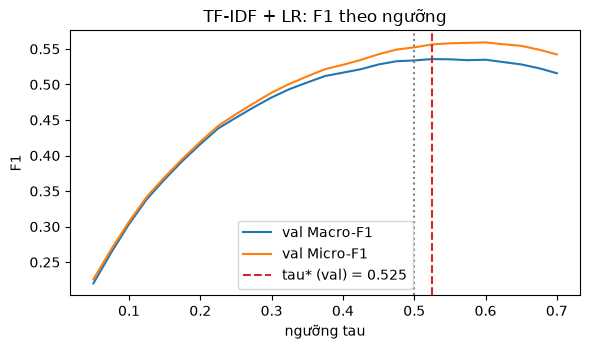

tau*(val)=0.525 | val Macro-F1: 0.5357 (tau=0.5: 0.5338)
Test Macro-F1 tại tau*: 0.5508 (tau=0.5: 0.5482)


In [7]:
# Quét ngưỡng chung tau từ 0.05 đến 0.70 và vẽ F1. tau* chọn theo val Macro-F1 cao nhất;
# sau đó test chỉ được BÁO CÁO tại tau* và tại 0.5 (xem việc chỉnh ngưỡng có giúp không), không dùng test để chọn ngưỡng.
import matplotlib.pyplot as plt
taus = np.round(np.arange(0.05, 0.71, 0.025), 3)
sweep = pd.DataFrame({'tau': taus,
    'val_macro_f1': [compute_metrics(Y['val'], P['val'], t)['macro_f1'] for t in taus],
    'val_micro_f1': [compute_metrics(Y['val'], P['val'], t)['micro_f1'] for t in taus],
    'test_macro_f1': [compute_metrics(Y['test'], P['test'], t)['macro_f1'] for t in taus]})
sweep.to_csv('../results/tables/threshold_sweep_tfidf_lr.csv', index=False)
tau_best = float(sweep.loc[sweep.val_macro_f1.idxmax(), 'tau'])
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(sweep.tau, sweep.val_macro_f1, label='val Macro-F1'); ax.plot(sweep.tau, sweep.val_micro_f1, label='val Micro-F1')
ax.axvline(0.5, ls=':', c='gray'); ax.axvline(tau_best, ls='--', c='C3', label=f'tau* (val) = {tau_best}')
ax.set_xlabel('ngưỡng tau'); ax.set_ylabel('F1'); ax.set_title('TF-IDF + LR: F1 theo ngưỡng'); ax.legend(); plt.tight_layout()
plt.savefig('../results/figures/threshold_sweep_tfidf_lr.png'); plt.show()
print(f'tau*(val)={tau_best} | val Macro-F1: {sweep.val_macro_f1.max():.4f} (tau=0.5: {compute_metrics(Y["val"], P["val"])["macro_f1"]:.4f})')
print(f'Test Macro-F1 tại tau*: {compute_metrics(Y["test"], P["test"], tau_best)["macro_f1"]:.4f} (tau=0.5: {res["test"]["macro_f1"]:.4f})')